# Jamnagar Crude Slate Model v3: Venezuelan Merey vs Russian Urals (live-data edition)

**Question:** Does swapping Russian Urals for heavy, high-sulfur Venezuelan Merey make Reliance more money per barrel at today's prices, and what discount does Merey need to be worth it?

**Pricing date:** 22 Oct 2026 (live pull via browser, 13:50 IST). Every input is tagged in the table below:

* **Sourced**: a published market figure, with source and date.
* **Estimate**: not publicly available (refinery yields, unit costs, Reliance's exact contract terms). Each estimate has a **low** and **high** value, and the model runs all three cases.

`Net margin = Product value − Delivered crude − Processing cost + Sulfur credit`

> Author: Mishu Kumar · Educational research, not investment advice. Sources are listed at the end.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, replace
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
MEREY_C, URALS_C = "#B4532A", "#2F5D8A"
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_colwidth", 70)

## 1. Input register: sourced data vs estimates

Edit this table to update the model. It is also saved as `inputs.csv`.

In [2]:
S, E = "Sourced", "Estimate"
INPUTS = pd.DataFrame([
 # key,                 base,  low,   high,  type, unit,      source / basis
 ("brent",              112.3, 100.0, 120.0, S, "$/bbl", "Oilprice.com live futures, 22 Oct 2026 13:50 IST ($112.31)"),
 ("merey_diff",         -16.5, -20.4, -12.0, S, "$/bbl", "Sep official Merey $93.75 (Oilprice/OPEC) vs EIA Sep Brent $114.16 = −20.4; JV deals −12/−13 (Reuters, 22 Sep); base = midpoint"),
 ("merey_freight",        9.0,   8.0,  10.0, S, "$/bbl", "Business Standard, 14 Aug 2026: Americas→India freight ~$8–10/bbl"),
 ("merey_insurance",      0.75,  0.4,   1.5, E, "$/bbl", "War-risk, cargo cover, OFAC screening; no public figure"),
 ("urals_dap_diff",       0.0,  -2.0,   8.0, S, "$/bbl", "Baird Maritime/Reuters, 15 Oct 2026: Urals DAP India ~parity to Dated Brent; peaked +$8 in Sep"),
 ("crack_lpg",          -20.0, -30.0, -10.0, E, "$/bbl", "No current Asian LPG crack found"),
 ("crack_gasoline",      23.0,  15.0,  50.0, S, "$/bbl", "Quantum (QCI), 21 Oct 2026: Singapore 92 RON $132.42/b FOB vs Brent ~$109.3 same day"),
 ("crack_jet",           68.0,  58.0,  78.0, E, "$/bbl", "Gasoil less ~$2 (QCI: Asian jet E/W at 6-month lows, Oct 2026); level not public"),
 ("crack_diesel",        70.0,  60.0,  78.0, S, "$/bbl", "QCI, 21 Oct 2026: Singapore gasoil 10ppm $179.81/b FOB, Nov crack $72.21 vs Dubai; M1 crack $64.75 on 16 Oct"),
 ("crack_fuel_oil",       2.0, -10.0,   8.0, S, "$/bbl", "TradingView, 22 Oct 2026: Singapore 380cst vs Dubai crack ~$3.3 (indicative; volatile)"),
 ("lng_usd_mmbtu",       29.55, 20.0,  35.0, S, "$/MMBtu", "Oilprice.com, JKM LNG $29.55 (2-day delay, ~20 Oct 2026); values petcoke gasified to replace LNG"),
 ("sulfur_fob",         835.0, 600.0, 900.0, S, "$/t", "Argus, 30 Sep 2026: QatarEnergy Oct sulphur $835/t FOB (Sep $880)"),
 ("sulfur_realisation",   0.85,  0.70,  0.95, E, "share", "Reliance netback vs Qatar FOB benchmark"),
 ("venez_kbd",          280.0, 200.0, 400.0, E, "kb/d", "Kpler: India Oct arrivals ~350–465 kb/d; Reliance share assumed ~80%"),
 ("usd_inr",             94.5,  93.0,  96.0, S, "₹/$", "Goodreturns ticker, 21 Oct 2026 (~94.5)"),
 ("merey_api",           16.0,  15.5,  16.5, S, "°API", "Merey 16 grade spec (Shale24)"),
 ("merey_sulfur_pct",     2.5,   2.4,   2.7, S, "%", "Merey 16 typical assay"),
 ("urals_api",           31.0,  30.0,  32.0, S, "°API", "Urals typical assay"),
 ("urals_sulfur_pct",     1.7,   1.5,   1.8, S, "%", "Urals typical assay"),
 ("base_opex",            3.0,   2.5,   3.5, E, "$/bbl", "Jamnagar cash cost; not disclosed"),
 ("opex_per_pct_s",       0.6,   0.4,   1.0, E, "$/bbl per %S", "Hydrotreating + hydrogen cost; H2 dearer with LNG high"),
 ("opex_per_api_below_30",0.10,  0.05,  0.15, E, "$/bbl per °", "Coking/resid upgrading penalty"),
], columns=["key", "base", "low", "high", "type", "unit", "source"]).set_index("key")
INPUTS.to_csv("inputs.csv")

# Yields are estimates (no public Jamnagar assay-LP output). Volume fractions, sum to 1.
YIELDS = {
 "merey": dict(lpg=.03, gasoline=.22, jet=.11, diesel=.44, fuel_oil=.04, petcoke=.11, fuel_loss=.05),
 "urals": dict(lpg=.03, gasoline=.25, jet=.12, diesel=.45, fuel_oil=.05, petcoke=.05, fuel_loss=.05),
}
for k, y in YIELDS.items():
    assert abs(sum(y.values()) - 1) < 1e-9, k

summary = INPUTS.groupby("type").size()
print(f"{summary.get(S,0)} sourced inputs, {summary.get(E,0)} estimates (+ yield vectors, all estimates)")
display(INPUTS[["base", "low", "high", "type", "unit", "source"]])

14 sourced inputs, 8 estimates (+ yield vectors, all estimates)


,base,low,high,type,unit,source
key,,,,,,
brent,112.30,100.00,120.00,Sourced,$/bbl,"Oilprice.com live futures, 22 Oct 2026 13:50 IST ($112.31)"
merey_diff,-16.50,-20.40,-12.00,Sourced,$/bbl,Sep official Merey $93.75 (Oilprice/OPEC) vs EIA Sep Brent $114.16...
merey_freight,9.00,8.00,10.00,Sourced,$/bbl,"Business Standard, 14 Aug 2026: Americas→India freight ~$8–10/bbl"
merey_insurance,0.75,0.40,1.50,Estimate,$/bbl,"War-risk, cargo cover, OFAC screening; no public figure"
urals_dap_diff,0.00,-2.00,8.00,Sourced,$/bbl,"Baird Maritime/Reuters, 15 Oct 2026: Urals DAP India ~parity to Da..."
crack_lpg,-20.00,-30.00,-10.00,Estimate,$/bbl,No current Asian LPG crack found
crack_gasoline,23.00,15.00,50.00,Sourced,$/bbl,"Quantum (QCI), 21 Oct 2026: Singapore 92 RON $132.42/b FOB vs Bren..."
crack_jet,68.00,58.00,78.00,Estimate,$/bbl,"Gasoil less ~$2 (QCI: Asian jet E/W at 6-month lows, Oct 2026); le..."
crack_diesel,70.00,60.00,78.00,Sourced,$/bbl,"QCI, 21 Oct 2026: Singapore gasoil 10ppm $179.81/b FOB, Nov crack ..."


## 2. Model

In [3]:
PETCOKE_MMBTU_PER_T, GASIFIER_EFF, GASIFIER_COST_T, PETCOKE_T_PER_BBL = 30.0, 0.65, 60.0, 0.16

def density_t_per_bbl(api):
    return 141.5 / (api + 131.5) * 0.159

def margins(p: dict) -> dict:
    """p = dict of input values (keys as in INPUTS). Returns per-bbl breakdown for both crudes."""
    b = p["brent"]
    price = dict(lpg=b + p["crack_lpg"], gasoline=b + p["crack_gasoline"], jet=b + p["crack_jet"],
                 diesel=b + p["crack_diesel"], fuel_oil=b + p["crack_fuel_oil"], fuel_loss=0.0)
    petcoke_usd_t = PETCOKE_MMBTU_PER_T * GASIFIER_EFF * p["lng_usd_mmbtu"] - GASIFIER_COST_T
    price["petcoke"] = petcoke_usd_t * PETCOKE_T_PER_BBL
    sulfur_px = p["sulfur_fob"] * p["sulfur_realisation"]

    spec = {
      "merey": dict(delivered=b + p["merey_diff"] + p["merey_freight"] + p["merey_insurance"],
                    api=p["merey_api"], s=p["merey_sulfur_pct"]),
      "urals": dict(delivered=b + p["urals_dap_diff"], api=p["urals_api"], s=p["urals_sulfur_pct"]),
    }
    out = {}
    for c, sp in spec.items():
        pv = sum(YIELDS[c][k] * price[k] for k in YIELDS[c])
        opex = p["base_opex"] + p["opex_per_pct_s"] * sp["s"] + p["opex_per_api_below_30"] * max(0, 30 - sp["api"])
        s_t = density_t_per_bbl(sp["api"]) * sp["s"] / 100 * 0.97
        out[c] = dict(product_value=pv, delivered_cost=sp["delivered"], GRM=pv - sp["delivered"],
                      processing_cost=opex, sulfur_t_per_kbbl=s_t * 1000, sulfur_credit=s_t * sulfur_px,
                      net_margin=pv - sp["delivered"] - opex + s_t * sulfur_px)
    return out

def advantage(p):
    m = margins(p)
    return m["merey"]["net_margin"] - m["urals"]["net_margin"]

BASE = INPUTS["base"].to_dict()
def with_(**kw):
    q = dict(BASE); q.update(kw); return q
annual = lambda adv, p=BASE: adv * p["venez_kbd"] * 1000 * 365 / 1e6   # $ mn

## 3. Base case at 22 Oct 2026 prices

In [4]:
m = margins(BASE)
tbl = pd.DataFrame(m).rename(columns={"merey": "Merey (Venezuela)", "urals": "Urals (Russia, DAP)"})
display(tbl)
u = advantage(BASE)
print(f"Merey vs Urals: {u:+.2f} $/bbl  →  {annual(u):+,.0f} $ mn/yr  (≈ ₹{annual(u)*1e6*BASE['usd_inr']/1e7:+,.0f} crore) at {BASE['venez_kbd']:.0f} kb/d")

,Merey (Venezuela),"Urals (Russia, DAP)"
product_value,146.24,150.11
delivered_cost,105.55,112.30
GRM,40.69,37.81
processing_cost,5.90,4.02
sulfur_t_per_kbbl,3.70,2.28
sulfur_credit,2.63,1.62
net_margin,37.41,35.41


Merey vs Urals: +2.00 $/bbl  →  +205 $ mn/yr  (≈ ₹+1,934 crore) at 280 kb/d


### Margin bridge

The bridge shows where the advantage is won and lost.

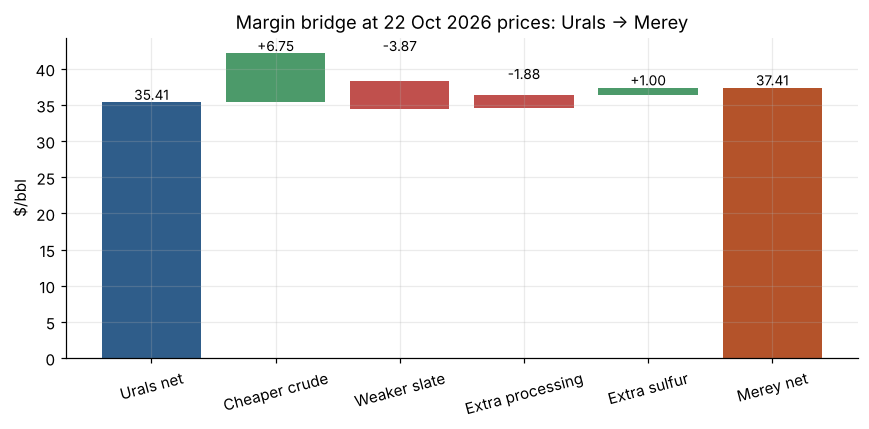

In [5]:
mu, mm = m["urals"], m["merey"]
steps = [("Urals net", mu["net_margin"]),
         ("Cheaper crude", mu["delivered_cost"] - mm["delivered_cost"]),
         ("Weaker slate", mm["product_value"] - mu["product_value"]),
         ("Extra processing", mu["processing_cost"] - mm["processing_cost"]),
         ("Extra sulfur", mm["sulfur_credit"] - mu["sulfur_credit"])]
fig, ax = plt.subplots(figsize=(8, 4))
run = 0
for i, (lab, v) in enumerate(steps):
    if i == 0:
        ax.bar(lab, v, color=URALS_C); run = v; ax.text(i, v + .3, f"{v:.2f}", ha="center", fontsize=9)
    else:
        ax.bar(lab, v, bottom=run if v >= 0 else run + v, color="#4C9A6A" if v >= 0 else "#C0504D")
        run += v; ax.text(i, max(run, run - v) + .3, f"{v:+.2f}", ha="center", fontsize=9)
ax.bar("Merey net", run, color=MEREY_C); ax.text(len(steps), run + .3, f"{run:.2f}", ha="center", fontsize=9)
ax.set_ylabel("$/bbl"); ax.set_title("Margin bridge at 22 Oct 2026 prices: Urals → Merey")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 4. Implied discount: what Reliance must be getting

Reliance doesn't publish its PDVSA price. Solve for the Merey differential at which the swap breaks even. If October imports are rising, Reliance's actual discount is probably at least this deep.

In [6]:
def breakeven_diff(p=BASE):
    return brentq(lambda d: advantage({**p, "merey_diff": d}), -60, 30)

be = breakeven_diff()
print(f"Break-even Merey differential at today's prices: Brent {be:+.2f} $/bbl")
print(f"Published reference points: PDVSA–JV deals −12 to −13 · intermediaries −16 · trader bids −18 to −20")

# How breakeven moved as Urals swung from +8 (Sep) to parity (Oct)
rows = [(ud, breakeven_diff(with_(urals_dap_diff=ud))) for ud in [-2, 0, 2, 4, 6, 8]]
display(pd.DataFrame(rows, columns=["Urals DAP diff ($/bbl)", "Merey break-even diff ($/bbl)"]).set_index("Urals DAP diff ($/bbl)"))

Break-even Merey differential at today's prices: Brent -14.50 $/bbl
Published reference points: PDVSA–JV deals −12 to −13 · intermediaries −16 · trader bids −18 to −20


,Merey break-even diff ($/bbl)
Urals DAP diff ($/bbl),
-2,-16.50
0,-14.50
2,-12.50
4,-10.50
6,-8.50
8,-6.50


## 5. The other two cases: low and high

Every input with a range is set to its low value, then its high value, while the sourced point values stay fixed. This shows how much of the answer rests on estimates.

In [7]:
est_keys = INPUTS.index[INPUTS.type == E]
def case(col, keys):
    q = dict(BASE); q.update(INPUTS.loc[keys, col].to_dict()); return q

cases = {
  "Base (all mid values)": BASE,
  "Estimate inputs LOW": case("low", est_keys),
  "Estimate inputs HIGH": case("high", est_keys),
  "Sept pricing (Urals +$8)": with_(urals_dap_diff=8.0),
  "Trader-level discount (Merey −$18)": with_(merey_diff=-18.0),
  "Diesel crack falls to $40": with_(crack_diesel=40.0, crack_jet=40.0),
  "Gasoline back to record $50": with_(crack_gasoline=50.0),
  "Sulfur collapses to $600": with_(sulfur_fob=600.0),
  "Freight spike to $12": with_(merey_freight=12.0),
  "OFAC licence pulled": with_(venez_kbd=0.0),
}
C = pd.DataFrame([dict(case=k, merey_net=margins(p)["merey"]["net_margin"], urals_net=margins(p)["urals"]["net_margin"],
                       adv_per_bbl=advantage(p) if p["venez_kbd"] > 0 else 0.0,
                       breakeven_diff=breakeven_diff(p), annual_usd_mn=annual(advantage(p), p))
                  for k, p in cases.items()]).set_index("case")
display(C)

,merey_net,urals_net,adv_per_bbl,breakeven_diff,annual_usd_mn
case,,,,,
Base (all mid values),37.41,35.41,2.00,-14.50,204.67
Estimate inputs LOW,37.60,34.46,3.14,-13.36,228.88
Estimate inputs HIGH,36.17,35.92,0.25,-16.25,36.63
Sept pricing (Urals +$8),37.41,27.41,10.00,-6.50,"1,022.27"
Trader-level discount (Merey −$18),38.91,35.41,3.50,-14.50,357.97
Diesel crack falls to $40,21.13,18.55,2.58,-13.92,263.95
Gasoline back to record $50,43.35,42.16,1.19,-15.31,121.89
Sulfur collapses to $600,36.67,34.95,1.72,-14.78,175.77
Freight spike to $12,34.41,35.41,-1.00,-17.50,-101.93


## 6. Tornado: each input swung across its low–high range

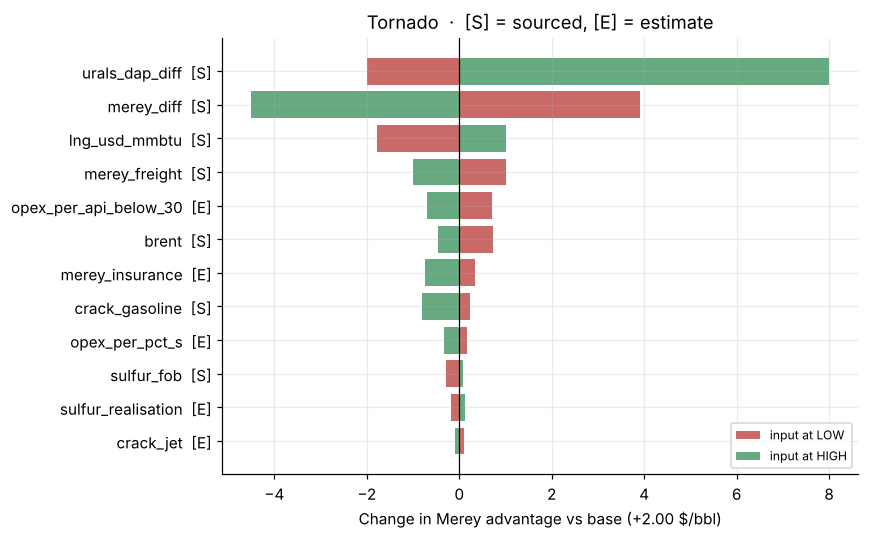

In [8]:
rows = []
for k in INPUTS.index:
    if k in ("venez_kbd", "usd_inr"):
        continue   # don't affect $/bbl
    lo, hi = advantage(with_(**{k: INPUTS.loc[k, "low"]})), advantage(with_(**{k: INPUTS.loc[k, "high"]}))
    rows.append((k, INPUTS.loc[k, "type"], lo - u, hi - u))
tor = pd.DataFrame(rows, columns=["input", "type", "at_low", "at_high"])
tor["range"] = (tor.at_high - tor.at_low).abs()
tor = tor.sort_values("range").tail(12)

fig, ax = plt.subplots(figsize=(8, 5))
labels = [f"{r.input}  [{'S' if r.type == S else 'E'}]" for r in tor.itertuples()]
ax.barh(labels, tor.at_low, color="#C0504D", alpha=.85, label="input at LOW")
ax.barh(labels, tor.at_high, color="#4C9A6A", alpha=.85, label="input at HIGH")
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel(f"Change in Merey advantage vs base ({u:+.2f} $/bbl)")
ax.set_title("Tornado  ·  [S] = sourced, [E] = estimate"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

## 7. Heatmap: Merey discount × freight (the two biggest sourced drivers)

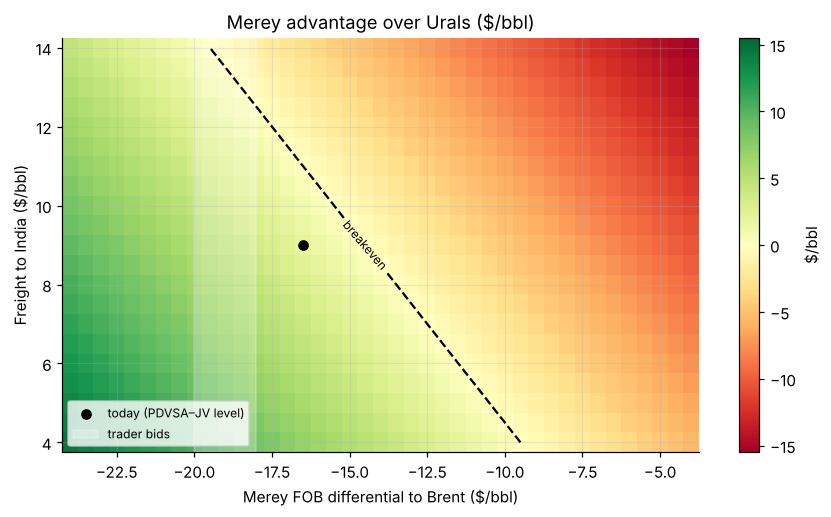

In [9]:
discs = np.arange(-24, -3.9, 0.5); frts = np.arange(4, 14.1, 0.5)
grid = np.array([[advantage(with_(merey_diff=d, merey_freight=f)) for d in discs] for f in frts])
fig, ax = plt.subplots(figsize=(8, 4.8))
lim = np.abs(grid).max()
im = ax.pcolormesh(discs, frts, grid, cmap="RdYlGn", vmin=-lim, vmax=lim, shading="nearest")
cs = ax.contour(discs, frts, grid, levels=[0], colors="black", linestyles="--"); ax.clabel(cs, fmt="breakeven", fontsize=8)
ax.scatter([BASE["merey_diff"]], [BASE["merey_freight"]], color="black", zorder=5, label="today (PDVSA–JV level)")
ax.axvspan(-20, -18, color="white", alpha=.25, label="trader bids")
ax.set_xlabel("Merey FOB differential to Brent ($/bbl)"); ax.set_ylabel("Freight to India ($/bbl)")
ax.set_title("Merey advantage over Urals ($/bbl)"); ax.legend(loc="lower left", fontsize=8)
fig.colorbar(im, ax=ax, label="$/bbl"); plt.tight_layout(); plt.show()

## 8. Monte Carlo over all ranges

10,000 draws. Each input with a range is drawn from a triangular distribution (low, base, high). Sourced and estimated inputs both vary, because even sourced prices move.

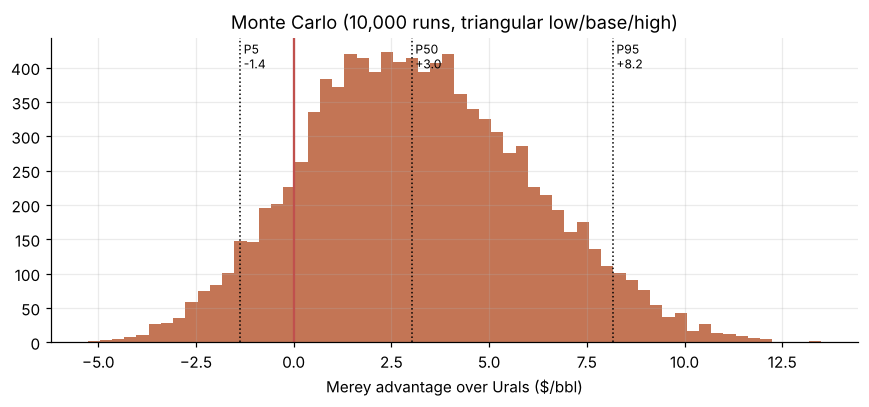

P(Merey beats Urals) = 86.8%   ·   P5 / P50 / P95 = -1.37 / +3.02 / +8.17 $/bbl

Inputs most correlated with the outcome:


,correlation
urals_dap_diff,0.75
merey_diff,-0.59
lng_usd_mmbtu,0.18
merey_freight,-0.15
opex_per_api_below_30,-0.10
brent,-0.09


In [10]:
rng = np.random.default_rng(7); N = 10_000
draw_keys = [k for k in INPUTS.index if INPUTS.loc[k, "low"] != INPUTS.loc[k, "high"]]
D = {k: rng.triangular(INPUTS.loc[k, "low"], INPUTS.loc[k, "base"], INPUTS.loc[k, "high"], N) for k in draw_keys}
res = np.array([advantage({**BASE, **{k: D[k][i] for k in draw_keys}}) for i in range(N)])

p5, p50, p95 = np.percentile(res, [5, 50, 95])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(res, bins=60, color=MEREY_C, alpha=.8); ax.axvline(0, color="#C0504D", lw=1.5)
for v, lab in [(p5, "P5"), (p50, "P50"), (p95, "P95")]:
    ax.axvline(v, color="black", ls=":", lw=1); ax.text(v, ax.get_ylim()[1]*.9, f" {lab}\n {v:+.1f}", fontsize=8)
ax.set_xlabel("Merey advantage over Urals ($/bbl)"); ax.set_title("Monte Carlo (10,000 runs, triangular low/base/high)")
plt.tight_layout(); plt.show()

corr = pd.Series({k: np.corrcoef(D[k], res)[0, 1] for k in draw_keys}).sort_values(key=abs, ascending=False)
print(f"P(Merey beats Urals) = {(res > 0).mean():.1%}   ·   P5 / P50 / P95 = {p5:+.2f} / {p50:+.2f} / {p95:+.2f} $/bbl")
print("\nInputs most correlated with the outcome:"); display(corr.head(6).to_frame("correlation"))

## 9. Summary

In [11]:
s_gap = mm["sulfur_credit"] - mu["sulfur_credit"]
print(f"""At 22 Oct 2026 prices, with Merey at Brent {BASE['merey_diff']:+.1f} (midpoint of reported range):
  Merey vs Urals = {u:+.2f} $/bbl ({annual(u):+,.0f} $ mn/yr at {BASE['venez_kbd']:.0f} kb/d).
  Break-even Merey differential = Brent {be:+.1f} $/bbl.

Merey wins on a cheaper delivered barrel ({mu['delivered_cost'] - mm['delivered_cost']:+.2f} $/bbl) and, with JKM LNG at ${BASE['lng_usd_mmbtu']:.1f}/MMBtu, its extra petcoke is valuable as gasifier feed.
Urals has fallen from +$8 (Sep) to ~parity (Oct), and ${BASE['crack_diesel']:.0f} diesel / ${BASE['crack_gasoline']:.0f} gasoline cracks make
Merey's lighter-product shortfall costly ({mm['product_value'] - mu['product_value']:+.2f} $/bbl).
Sulfur at ${BASE['sulfur_fob']:.0f}/t is now material: Merey's extra sulfur is worth {s_gap:+.2f} $/bbl.

Estimate ranges move the answer from {C.loc['Estimate inputs LOW','adv_per_bbl']:+.2f} (low case) to {C.loc['Estimate inputs HIGH','adv_per_bbl']:+.2f} (high case) $/bbl.
Monte Carlo: Merey wins in {(res > 0).mean():.0%} of runs.
At September's Urals premium (+$8), Merey was worth {C.loc['Sept pricing (Urals +$8)','adv_per_bbl']:+.2f} $/bbl, consistent with
the October import surge, since those cargoes were priced while Urals was expensive.""")

At 22 Oct 2026 prices, with Merey at Brent -16.5 (midpoint of reported range):
  Merey vs Urals = +2.00 $/bbl (+205 $ mn/yr at 280 kb/d).
  Break-even Merey differential = Brent -14.5 $/bbl.

Merey wins on a cheaper delivered barrel (+6.75 $/bbl) and, with JKM LNG at $29.6/MMBtu, its extra petcoke is valuable as gasifier feed.
Urals has fallen from +$8 (Sep) to ~parity (Oct), and $70 diesel / $23 gasoline cracks make
Merey's lighter-product shortfall costly (-3.87 $/bbl).
Sulfur at $835/t is now material: Merey's extra sulfur is worth +1.00 $/bbl.

Estimate ranges move the answer from +3.14 (low case) to +0.25 (high case) $/bbl.
Monte Carlo: Merey wins in 87% of runs.
At September's Urals premium (+$8), Merey was worth +10.00 $/bbl, consistent with
the October import surge, since those cargoes were priced while Urals was expensive.


## Data still missing (for the next version)
| Input | Why it's missing | Where to get it |
|---|---|---|
| Exact Asian jet and LPG cracks | Paywalled (Platts/Argus/QCI) | Bloomberg/Eikon at NIA library |
| Reliance's actual PDVSA price | Not disclosed | Infer via §4; PPAC country-wise import value ÷ volume |
| Jamnagar yields and unit costs | Proprietary | Approximate with a published Merey/Urals assay + LP (AMPL/PuLP) |
| Reliance Q2 FY27 GRM | Results not yet released | RIL exchange filing (Q1 FY27 O2C EBITDA was ₹17,010 cr, margin ~8.4%) |

## Sources
- Trading Economics, Brent crude (22 Oct 2026)
- Rio Times / Reuters, *Venezuela's Merey crude: traders demand deeper discounts as freight jumps* (22 Sep 2026)
- Business Standard, *Venezuelan crude turns costly for India as discounts shrink, freight surges* (14 Aug 2026)
- Baird Maritime / Reuters, *Russian crude premiums in India slip as Asian demand softens* (15 Oct 2026)
- China–Global South Project, *Asian gasoline margins slide as Chinese barrels return* (17 Oct 2026)
- Energy News Beat, diesel cracks (24 Aug 2026); Discovery Alert citing Crux Investor, EU diesel margin (16 Oct 2026)
- Argus Media, *QatarEnergy drops October sulphur price by $45/t* (30 Sep 2026)
- Oilprice.com price charts (Brent, Urals, JKM, OPEC Merey Sep; 22 Oct 2026); EIA Brent monthly spot (released 21 Oct 2026); Quantum Commodity Intelligence East of Suez reports (16–21 Oct 2026); TradingView Singapore 380cst crack
- Kpler via Business Today (7 Oct 2026); Goodreturns (USD/INR, 21 Oct 2026); Observer Voice (RIL Q1 FY27 O2C, 18 Jul 2026)